### Import Modules

In [5]:
import numpy as np
import pandas as pd
import os
from scipy.integrate import trapz
import utils.segment_isc_utils 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.warn("deprecated", DeprecationWarning)
warnings.simplefilter("ignore")
from scipy.stats import pearsonr

### Define Helper Function

In [56]:
import numpy as np
import pandas as pd

def sliding_window_split_half_isc(df_group, win_size, step_size, fs, n_splits=50):
    """
    Calculates Dynamic ISC using a Bootstrapped Split-Half approach.
    
    For each window, subjects are randomly divided into two halves multiple times (n_splits).
    The correlation is calculated between the Mean Signal of Half A and the Mean Signal of Half B.
    
    Args:
        df_group: DataFrame or Array of shape (Time, Subjects)
        win_size: Window size in samples
        step_size: Step size in samples
        fs: Sampling rate
        n_splits: Number of random permutations to average per window (default 50)
        
    Returns:
        DataFrame with ['Time_Sec', 'Mean_r']
    """
    data = df_group.values
    n_samples, n_subs = data.shape
    
    # Safety check
    if n_subs < 2:
        raise ValueError("Need at least 2 subjects to perform split-half ISC.")
    
    half_size = n_subs // 2
    results = []
    
    # Iterate through time with sliding window
    for start_idx in range(0, n_samples - win_size, step_size):
        end_idx = start_idx + win_size
        time_sec = end_idx / fs  # Causal timestamp
        
        # Extract window data (Time x Subjects)
        window_data = data[start_idx:end_idx, :]
        
        split_correlations = []
        
        # --- BOOTSTRAP PERMUTATION LOOP ---
        for _ in range(n_splits):
            # 1. Randomly shuffle indices
            shuffled_indices = np.random.permutation(n_subs)
            
            # 2. Split into two groups
            # If n_subs is odd, the last subject is excluded from this specific permutation
            idx_a = shuffled_indices[:half_size]
            idx_b = shuffled_indices[half_size : 2*half_size]
            
            # 3. Calculate Means of each half
            mean_a = np.mean(window_data[:, idx_a], axis=1)
            mean_b = np.mean(window_data[:, idx_b], axis=1)
            
            # 4. Calculate Correlation
            # Check for flatlines (std=0) to avoid NaNs
            if np.std(mean_a) == 0 or np.std(mean_b) == 0:
                r = np.nan
            else:
                r = np.corrcoef(mean_a, mean_b)[0, 1]
            
            split_correlations.append(r)
        
        # --- FISHER Z-AVERAGE ---
        clean_rs = [x for x in split_correlations if not np.isnan(x)]
        
        if len(clean_rs) > 0:
            # Clip to avoid infinity in arctanh
            z_vals = np.arctanh(np.clip(clean_rs, -0.999, 0.999))
            mean_r = np.tanh(np.mean(z_vals))
        else:
            mean_r = 0 
            
        results.append({'Time_Sec': time_sec, 'Mean_r': mean_r})
        
    return pd.DataFrame(results)
    
def sliding_window_within_group_isc(df_group, win_size, step_size, fs):
    """
    Calculates Dynamic ISC within a single group using Leave-One-Out (LOO) approach.
    
    Args:
        df_group: DataFrame or Array of shape (Time, Subjects)
        win_size: Window size in samples
        step_size: Step size in samples
        fs: Sampling rate (for time axis calculation)
        
    Returns:
        DataFrame with ['Time_Sec', 'Mean_r']
    """
    data = df_group.values
    n_samples, n_subs = data.shape
    
    results = []
    
    # Iterate through time with sliding window
    for start_idx in range(0, n_samples - win_size, step_size):
        end_idx = start_idx + win_size
        time_sec = end_idx / fs  # Causal timestamp (time at end of window)
        
        # Extract window data (Time x Subjects)
        window_data = data[start_idx:end_idx, :]
        
        loo_correlations = []
        
        # --- LEAVE-ONE-OUT LOOP ---
        for i in range(n_subs):
            # 1. Subject i
            subject_ts = window_data[:, i]
            
            # 2. Average of everyone else (LOO)
            others_idx = [j for j in range(n_subs) if j != i]
            group_mean_ts = np.mean(window_data[:, others_idx], axis=1)
            
            # 3. Correlation (handle potential flat-lines/zeros)
            if np.std(subject_ts) == 0 or np.std(group_mean_ts) == 0:
                r = np.nan # Undefined correlation
            else:
                r = np.corrcoef(subject_ts, group_mean_ts)[0, 1]
            
            loo_correlations.append(r)
        
        # --- FISHER Z-AVERAGE ---
        # Convert r -> z, take mean, convert z -> r
        # Filter out NaNs if any bad segments occurred
        clean_rs = [x for x in loo_correlations if not np.isnan(x)]
        
        if len(clean_rs) > 0:
            z_vals = np.arctanh(np.clip(clean_rs, -0.999, 0.999))
            mean_r = np.tanh(np.mean(z_vals))
        else:
            mean_r = 0 # or NaN
            
        results.append({'Time_Sec': time_sec, 'Mean_r': mean_r})
        
    return pd.DataFrame(results)

### Run Sliding Window ISC

In [57]:
DATA_DIR        = "../data/02_processed_combined_data"
CONDITIONS_FILE = "../data/sub_conditions.csv"
OUTPUT_PLOT    = "Figure4_DynISC.png"


# Constants
FS = 20
WINDOW_SECONDS = 15
STEP_SECONDS = 1
WIN_SIZE = int(WINDOW_SECONDS * FS)
STEP_SIZE = int(STEP_SECONDS * FS)

signals = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']
signal_labels = {
    'Gaze_X': 'Gaze X', 'Gaze_Y': 'Gaze Y',
    'Pupil_Mean': 'Pupil', 'Heart_Rate': 'Heart Rate', 'GSR': 'GSR'}

pc_subs  = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PC')
pcm_subs = utils.segment_isc_utils.get_subjects_by_condition(CONDITIONS_FILE, 'PCM')


all_results = []


for signal in signals:
    print(f"  Processing {signal}...")

    d_pc = utils.segment_isc_utils.load_physio_data(DATA_DIR, pc_subs, signal)
    d_pcm = utils.segment_isc_utils.load_physio_data(DATA_DIR, pcm_subs, signal)
        
 # 2. COMPUTE ISC FOR GROUP 1 (PC)
    res_pc = sliding_window_split_half_isc(d_pc, WIN_SIZE, STEP_SIZE, FS)
    res_pc['Condition'] = 'Main Movie'
    res_pc['Signal'] = signal
    
    # 3. COMPUTE ISC FOR GROUP 2 (PCM)
    res_pcm = sliding_window_split_half_isc(d_pcm, WIN_SIZE, STEP_SIZE, FS)
    res_pcm['Condition'] = 'Manipulated Movie'
    res_pcm['Signal'] = signal
    
    all_results.append(res_pc)
    all_results.append(res_pcm)

# Combine all results
df_viz = pd.concat(all_results, ignore_index=True)


  Processing Gaze_X...
  Processing Gaze_Y...
  Processing Pupil_Mean...
  Processing Heart_Rate...
  Processing GSR...


### Plot

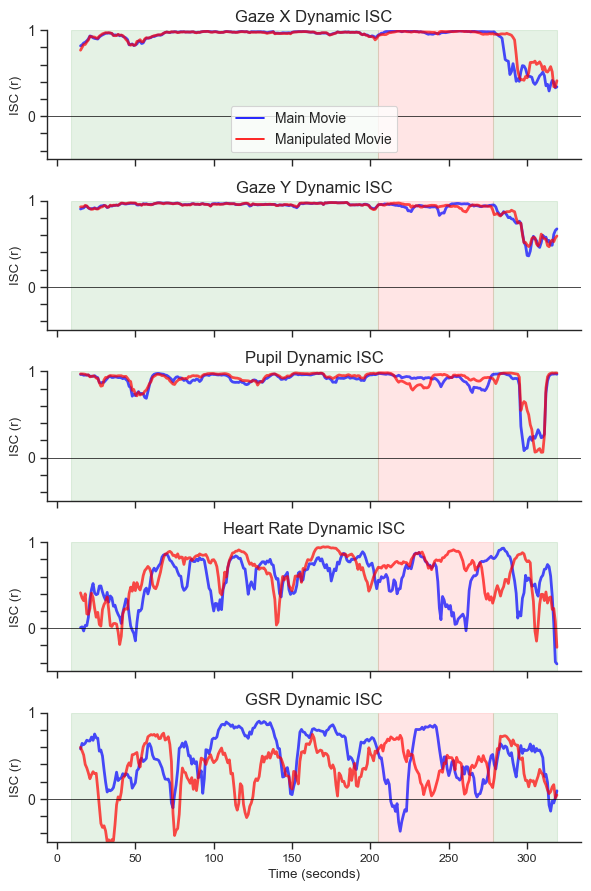

In [62]:

BRANCH_TIME = 205
sns.set_theme(font='Arial')
sns.set(style="ticks", context="paper")


fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(6, 9), sharex=True)
#fig.suptitle('      Dynamic ISC')
palette = {'Main Movie': 'blue', 'Manipulated Movie': 'red'} # Blue vs Orange

for i, sig in enumerate(signals):
    ax = axes[i]
    subset = df_viz[df_viz['Signal'] == sig]
    
    # Plot using Seaborn lineplot
    sns.lineplot(data=subset, x='Time_Sec', y='Mean_r', hue='Condition', alpha = 0.7,
                 palette=palette, ax=ax, linewidth=2)
    
    ax.set_title(signal_labels[sig] + ' Dynamic ISC', loc='center', fontsize=12)
    ax.set_ylabel("ISC (r)")
    ax.axhline(0, color='black', lw=0.5)

    ax.axvspan(9, BRANCH_TIME, color='green', alpha=0.1)
    ax.axvspan(BRANCH_TIME, 278, color='red', alpha=0.1)
    ax.axvspan(278, 319, color='green', alpha=0.1)
    
    ax.set_ylim(-0.5, 1.0)
    y_ticks = [-0.4, -0.2, 0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
    ax.set_yticks(y_ticks)
    y_labels = ["", "", "0", "", "", "", "", "1"]
    ax.set_yticklabels(y_labels, fontsize=10)

    
    # Only show legend on the first plot
    if i == 0:
        ax.legend(loc='lower center', fontsize=10)
    else:
        ax.get_legend().remove()

axes[-1].set_xlabel("Time (seconds)")
sns.despine()
plt.tight_layout()
plt.savefig(OUTPUT_PLOT, dpi=300)

plt.show()